In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
df=pd.read_csv("swiftcart_store_data.csv")

## Data Exploration & Understanding

In [45]:
df.shape

(31047, 21)

In [47]:
df.columns.tolist()

['index',
 'Order ID',
 'Cust ID',
 'Gender',
 'Age',
 'Age Group',
 'Date',
 'Month',
 'Status',
 'Channel ',
 'SKU',
 'Category',
 'Size',
 'Qty',
 'currency',
 'Amount',
 'ship-city',
 'ship-state',
 'ship-postal-code',
 'ship-country',
 'B2B']

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31047 entries, 0 to 31046
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   index             29967 non-null  object 
 1   Order ID          29967 non-null  object 
 2   Cust ID           29968 non-null  object 
 3   Gender            29972 non-null  object 
 4   Age               29962 non-null  object 
 5   Age Group         29979 non-null  object 
 6   Date              30582 non-null  float64
 7   Month             30582 non-null  object 
 8   Status            31047 non-null  object 
 9   Channel           31047 non-null  object 
 10  SKU               31047 non-null  object 
 11  Category          31047 non-null  object 
 12  Size              31047 non-null  object 
 13  Qty               31047 non-null  int64  
 14  currency          31047 non-null  object 
 15  Amount            31047 non-null  int64  
 16  ship-city         31047 non-null  object

In [51]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
index,29967,29950,155290.0,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order ID,29967,27555,403-4984515-8861958,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cust ID,29968,27493,4984515.0,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,29972,2,Women,20813,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,29962,74,28.0,804,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age Group,29979,3,Adult,15030,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,30582.0,NaN,NaN,NaN,45119.190864,15106.052476,44565.0,44626.0,44718.0,44810.0,849642.0
Month,30582,12,Mar,2793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,31047,4,Delivered,28641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Channel,31047,7,Amazon,11016,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [52]:
for col in df.columns:
    print(f"\n{'='*50}")
    print(f"Column: {col}")
    print("Unique values:", df[col].nunique(dropna=False))
    print("Sample values:")
    print(df[col].drop_duplicates().head(10).tolist())


Column: index
Unique values: 29951
Sample values:
['1.0', '2.0', '3.0', '4.0', '5.0', '6.0', '7.0', '8.0', '9.0', '10.0']

Column: Order ID
Unique values: 27556
Sample values:
['171-1029312-3038738', '405-2183842-2225946', '171-1641533-8921966', '404-7490807-6300351', '403-9293516-4577154', '407-1298130-0368305', '171-5561216-3398711', '408-2935263-2935550', '404-2648970-9042715', '408-0265357-4939534']

Column: Cust ID
Unique values: 27494
Sample values:
['1029312.0', '2183842.0', '1641533.0', '7490807.0', '9293516.0', '1298130.0', '5561216.0', '2935263.0', '2648970.0', '265357.0']

Column: Gender
Unique values: 3
Sample values:
['Women', 'Men', nan]

Column: Age
Unique values: 75
Sample values:
[nan, '29.0', '67.0', '20.0', '62.0', '49.0', '23.0', '70.0', '75.0', '43.0']

Column: Age Group
Unique values: 4
Sample values:
['Adult', 'Teenager', 'Senior', nan]

Column: Date
Unique values: 44
Sample values:
[44899.0, nan, 44869.0, 447180.0, 44838.0, 715488.0, 44808.0, 44777.0, 357744.0,

**1.Checking unique values**

In [56]:
for col in df.columns:
    print(col, ":", df[col].nunique(dropna=False))

index : 29951
Order ID : 27556
Cust ID : 27494
Gender : 3
Age : 75
Age Group : 4
Date : 44
Month : 13
Status : 4
Channel  : 7
SKU : 5287
Category : 8
Size : 11
Qty : 14
currency : 1
Amount : 769
ship-city : 2603
ship-state : 50
ship-postal-code : 4959
ship-country : 1
B2B : 2


**2.checking missing values**

In [59]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing[missing["Missing_Count"] > 0].sort_values(
    "Missing_Count", ascending=False
))

,Missing_Count,Missing_Percentage
Age,1085,3.49
index,1080,3.48
Order ID,1080,3.48
Cust ID,1079,3.48
Gender,1075,3.46
Age Group,1068,3.44
Date,465,1.50
Month,465,1.50


**3.checking dupliactes**

In [62]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [64]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

In [66]:
df.rename(columns={
    'cust_id': 'customer_id',
    'qty': 'quantity'
}, inplace=True)

In [68]:
df.columns

Index(['index', 'order_id', 'customer_id', 'gender', 'age', 'age_group',
       'date', 'month', 'status', 'channel', 'sku', 'category', 'size',
       'quantity', 'currency', 'amount', 'ship-city', 'ship-state',
       'ship-postal-code', 'ship-country', 'b2b'],
      dtype='object')

In [70]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

print(df.columns.tolist())

['index', 'order_id', 'customer_id', 'gender', 'age', 'age_group', 'date', 'month', 'status', 'channel', 'sku', 'category', 'size', 'quantity', 'currency', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'ship_country', 'b2b']


In [72]:
missing_rows = df[df.isnull().any(axis=1)]

print("Rows containing at least one missing value:", len(missing_rows))

display(missing_rows.head(20))

Rows containing at least one missing value: 6622


,index,order_id,customer_id,gender,age,age_group,date,month,status,channel,...,category,size,quantity,currency,amount,ship_city,ship_state,ship_postal_code,ship_country,b2b
0,1.0,171-1029312-3038738,1029312.0,Women,NaN,Adult,44899.0,Dec,Delivered,Myntra,...,kurta,XXL,1,INR,376,MOHALI,PUNJAB,140301,IN,False
25,26.0,403-5438780-7231546,5438780.0,Women,37.0,NaN,44899.0,Dec,Delivered,Others,...,kurta,XXL,1,INR,533,INDORE,MADHYA PRADESH,452014,IN,False
37,38.0,NaN,6932218.0,Women,41.0,Adult,44899.0,Dec,Delivered,Myntra,...,Set,XS,1,INR,967,CHANDIGARH,CHANDIGARH,160036,IN,False
46,47.0,NaN,7694743.0,Women,46.0,Adult,44899.0,Dec,Delivered,Myntra,...,Set,S,1,INR,833,BENGALURU,KARNATAKA,562107,IN,False
50,51.0,NaN,4213846.0,Women,27.0,Teenager,44899.0,Dec,Delivered,Amazon,...,Set,M,1,INR,664,HYDERABAD,TELANGANA,500039,IN,False
53,54.0,171-2439278-5433152,2439278.0,Men,NaN,Adult,44899.0,Dec,Delivered,Myntra,...,Set,XS,1,INR,698,KHALILABAD,UTTAR PRADESH,272175,IN,False
54,55.0,405-8874360-4913961,8874360.0,NaN,23.0,Teenager,44899.0,Dec,Delivered,Others,...,Set,XXL,1,INR,1115,NEW DELHI,DELHI,110016,IN,False
55,NaN,408-4675134-5301129,4675134.0,Women,58.0,Senior,44899.0,Dec,Delivered,Meesho,...,Set,XXL,1,INR,507,HYDERABAD,TELANGANA,500008,IN,False
63,64.0,404-8169153-4411563,8169153.0,NaN,20.0,Teenager,44899.0,Dec,Delivered,Amazon,...,kurta,L,1,INR,399,Bangalore,KARNATAKA,560054,IN,False
71,72.0,406-7030051-2742704,7030051.0,Women,NaN,Adult,44899.0,Dec,Delivered,Myntra,...,kurta,XXL,1,INR,563,NEW DELHI,DELHI,110084,IN,False


**step 1: cleaning index**

In [75]:
# Fill missing index values based on row order
# Convert strings like '1.0' to numeric values
# Convert index to numeric first
df["index"] = pd.to_numeric(df["index"], errors="coerce")

# Fill missing values using row positions
missing_mask = df["index"].isna()
df["index"] = df["index"].where(
    ~missing_mask,
    pd.Series(np.arange(1, len(df) + 1), index=df.index)
)

# Convert to integer
df["index"] = df["index"].astype("int64")

In [77]:
print(df["index"].dtype)
print("Missing:", df["index"].isna().sum())
print("Unique index values:", df["index"].nunique())

int64
Missing: 0
Unique index values: 31036


In [79]:
print("Missing index values:", df["index"].isnull().sum())
print(df[["index", "order_id", "customer_id"]].head(10))

Missing index values: 0
   index             order_id customer_id
0      1  171-1029312-3038738   1029312.0
1      2  405-2183842-2225946   2183842.0
2      3  171-1641533-8921966   1641533.0
3      4  404-7490807-6300351   7490807.0
4      5  403-9293516-4577154   9293516.0
5      6  407-1298130-0368305   1298130.0
6      7  407-1298130-0368305   1298130.0
7      8  171-5561216-3398711   5561216.0
8      9  408-2935263-2935550   2935263.0
9     10  404-2648970-9042715   2648970.0


In [81]:
missing_pattern = (
    df.isnull()
    .groupby(list(df.columns))
    .size()
    .sort_values(ascending=False)
)

missing_pattern.head(20)

index  order_id  customer_id  gender  age    age_group  date   month  status  channel  sku    category  size   quantity  currency  amount  ship_city  ship_state  ship_postal_code  ship_country  b2b  
False  False     False        False   False  False      False  False  False   False    False  False     False  False     False     False   False      False       False             False         False    25286
                 True         False   False  False      False  False  False   False    False  False     False  False     False     False   False      False       False             False         False      920
                 False        True    False  False      False  False  False   False    False  False     False  False     False     False   False      False       False             False         False      902
                              False   False  True       False  False  False   False    False  False     False  False     False     False   False      False       False      

**step 1: Checking missing rows for identifiers**

In [84]:
display(
    df[
        df["order_id"].isna() |
        df["customer_id"].isna() |
        df["index"].isna()
    ].head(20)
)

,index,order_id,customer_id,gender,age,age_group,date,month,status,channel,...,category,size,quantity,currency,amount,ship_city,ship_state,ship_postal_code,ship_country,b2b
37,38,NaN,6932218.0,Women,41.0,Adult,44899.0,Dec,Delivered,Myntra,...,Set,XS,1,INR,967,CHANDIGARH,CHANDIGARH,160036,IN,False
46,47,NaN,7694743.0,Women,46.0,Adult,44899.0,Dec,Delivered,Myntra,...,Set,S,1,INR,833,BENGALURU,KARNATAKA,562107,IN,False
50,51,NaN,4213846.0,Women,27.0,Teenager,44899.0,Dec,Delivered,Amazon,...,Set,M,1,INR,664,HYDERABAD,TELANGANA,500039,IN,False
100,101,NaN,6522716.0,Men,78.0,Senior,NaN,Dec,Delivered,Myntra,...,Set,M,1,INR,852,NEW DELHI,DELHI,110034,IN,False
123,124,NaN,816846.0,Women,50.0,Senior,44899.0,Dec,Delivered,Flipkart,...,kurta,XL,1,INR,307,Coimbatore,TAMIL NADU,641031,IN,False
131,132,NaN,9605076.0,Men,59.0,Senior,44899.0,Dec,Delivered,Amazon,...,Set,L,1,INR,788,Buxar,BIHAR,802133,IN,False
137,138,NaN,1064158.0,Men,35.0,Adult,44899.0,Dec,Delivered,Myntra,...,Set,S,1,INR,664,Yacharam,TELANGANA,501509,IN,False
141,142,406-9626742-4153157,NaN,Men,63.0,Senior,44899.0,Dec,Delivered,Amazon,...,Western Dress,M,1,INR,771,MANMAD,MAHARASHTRA,423104,IN,False
145,146,NaN,NaN,Men,24.0,Teenager,44899.0,Dec,Delivered,Flipkart,...,Set,M,1,INR,967,Kollam,KERALA,691601,IN,False
158,159,408-7372776-3077164,NaN,Men,49.0,Adult,44899.0,Dec,Delivered,Myntra,...,Western Dress,M,1,INR,625,MUMBAI,MAHARASHTRA,400078,IN,False


**step2:cleaning customer id and order id**

In [87]:
# Rows where customer_id is missing but order_id is available
df.loc[
    df["customer_id"].isna() & df["order_id"].notna(),
    ["order_id", "customer_id"]
].head(10)

,order_id,customer_id
141,406-9626742-4153157,NaN
158,408-7372776-3077164,NaN
167,402-2642921-6231538,NaN
175,408-7238770-6140358,NaN
223,405-7420219-7316315,NaN
252,405-4215381-1387550,NaN
280,403-2921633-1318754,NaN
282,402-9822747-1695509,NaN
356,404-3874867-5497948,NaN
373,406-0431359-8413934,NaN


In [89]:
# Check whether missing customer IDs can be recovered
missing_customer = df[df["customer_id"].isna()]

order_customer_check = df[
    df["order_id"].isin(missing_customer["order_id"])
    & df["customer_id"].notna()
][["order_id", "customer_id"]].drop_duplicates()

display(order_customer_check.head(10))

,order_id,customer_id
37,NaN,6932218.0
46,NaN,7694743.0
50,NaN,4213846.0
100,NaN,6522716.0
123,NaN,816846.0
131,NaN,9605076.0
137,NaN,1064158.0
247,NaN,7926847.0
265,NaN,915050.0
284,NaN,2406097.0


In [91]:

# Fill only missing customer IDs when order_id is available
mask = df["customer_id"].isna() & df["order_id"].notna()

middle_value = (
    df.loc[mask, "order_id"]
    .astype(str)
    .str.extract(r"^\d+-(\d+)-\d+$")[0]
)

df.loc[mask, "customer_id"] = pd.to_numeric(
    middle_value, errors="coerce"
)

print("Missing customer_id:", df["customer_id"].isna().sum())


Missing customer_id: 41


This extracts the middle number from IDs such as 408-4675134-5301129 and uses 4675134 to fill the missing customer_id.

In [94]:
# Check missing order IDs
print("Missing order_id:", df["order_id"].isna().sum())
print("Rows with missing order_id but customer_id available:",
      (df["order_id"].isna() & df["customer_id"].notna()).sum())

Missing order_id: 1080
Rows with missing order_id but customer_id available: 1039


**step 3.checking date**

In [97]:
# Convert Excel serial dates to actual dates
df["date"] = pd.to_datetime(
    pd.to_numeric(df["date"], errors="coerce"),
    unit="D",
    origin="1899-12-30",
    errors="coerce"
)

print(df["date"].head(10))
print("Missing dates:", df["date"].isna().sum())

0   2022-12-04
1   2022-12-04
2   2022-12-04
3   2022-12-04
4   2022-12-04
5   2022-12-04
6   2022-12-04
7   2022-12-04
8   2022-12-04
9   2022-12-04
Name: date, dtype: datetime64[ns]
Missing dates: 488


In [99]:
# Derive month from date
df["month_from_date"] = df["date"].dt.strftime("%b")

# Compare existing month with derived month
check = df["month"].astype("string").str.strip().str.title()
mismatch = check.notna() & df["month_from_date"].notna() & (
    check != df["month_from_date"]
)

print("Month mismatches:", mismatch.sum())
print("Missing dates:", df["date"].isna().sum())

Month mismatches: 0
Missing dates: 488


**step4 :checking age**

In [101]:
# Convert age to numeric safely
df["age"] = pd.to_numeric(df["age"], errors="coerce")

print("Age data type:", df["age"].dtype)
print("Missing ages:", df["age"].isna().sum())
print("Age above 100:", (df["age"] > 100).sum())

Age data type: float64
Missing ages: 1091
Age above 100: 23


In [103]:
import numpy as np

# Replace invalid ages
df.loc[df["age"] > 100, "age"] = np.nan

# Fill missing ages with median
median_age = df["age"].median()
df["age"] = df["age"].fillna(median_age)

print("Missing ages:", df["age"].isna().sum())
print("Maximum age:", df["age"].max())
print("Median age used:", median_age)

Missing ages: 0
Maximum age: 78.0
Median age used: 37.0


In [106]:
df["age"] = df["age"].astype("int64")

print(df["age"].dtype)
print(df["age"].head())

int64
0    37
1    29
2    67
3    20
4    62
Name: age, dtype: int64


**step4: age group**

In [109]:
print(df["age_group"].value_counts(dropna=False))

age_group
Adult       15030
Teenager     9065
Senior       5884
NaN          1068
Name: count, dtype: int64


In [111]:
display(
    df.groupby("age_group", dropna=False)["age"]
      .agg(["min", "max", "count"])
)

,min,max,count
age_group,,,
Adult,30,49,15030
Senior,37,78,5884
Teenager,18,37,9065
NaN,18,78,1068


In [113]:
# Check age-group labels for each age
display(
    df[df["age_group"].isna()][["age", "age_group"]]
      .head(20)
)

,age,age_group
25,37,NaN
73,32,NaN
110,32,NaN
133,31,NaN
136,22,NaN
142,33,NaN
286,48,NaN
311,48,NaN
313,41,NaN
373,24,NaN


In [115]:
# Find the most common age group for each age
age_group_map = (
    df[df["age_group"].notna()]
    .groupby("age")["age_group"]
    .agg(lambda x: x.mode().iloc[0])
)

# Fill missing age groups using the mapping
mask = df["age_group"].isna()
df.loc[mask, "age_group"] = df.loc[mask, "age"].map(age_group_map)

print("Missing age_group:", df["age_group"].isna().sum())
print(df["age_group"].value_counts())

Missing age_group: 0
age_group
Adult       15560
Teenager     9407
Senior       6080
Name: count, dtype: int64


**step5 :checking gender**

In [118]:
print(df["gender"].value_counts(dropna=False))

gender
Women    20813
Men       9159
NaN       1075
Name: count, dtype: int64


In [120]:
df["gender"] = df["gender"].fillna("Unknown")

print(df["gender"].value_counts(dropna=False))
print("Missing gender:", df["gender"].isna().sum())

gender
Women      20813
Men         9159
Unknown     1075
Name: count, dtype: int64
Missing gender: 0


In [122]:
df.columns

Index(['index', 'order_id', 'customer_id', 'gender', 'age', 'age_group',
       'date', 'month', 'status', 'channel', 'sku', 'category', 'size',
       'quantity', 'currency', 'amount', 'ship_city', 'ship_state',
       'ship_postal_code', 'ship_country', 'b2b', 'month_from_date'],
      dtype='object')

In [124]:
print(df["month"].value_counts(dropna=False).sort_index())

month
Apr    2645
Aug    2580
Dec    2351
Feb    2709
Jan    2665
Jul    2540
Jun    2557
Mar    2793
May    2577
Nov    2345
Oct    2369
Sep    2451
NaN     465
Name: count, dtype: int64


In [126]:
df["month"] = (
    df["month"]
    .astype("string")
    .str.strip()
    .str.title()
)

In [128]:
valid_months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

print("Month values after standardization:")
print(df["month"].value_counts(dropna=False).sort_index())

print("\nInvalid month values:")
print(
    df.loc[
        df["month"].notna() & ~df["month"].isin(valid_months),
        "month"
    ].unique()
)

Month values after standardization:
month
Apr     2645
Aug     2580
Dec     2351
Feb     2709
Jan     2665
Jul     2540
Jun     2557
Mar     2793
May     2577
Nov     2345
Oct     2369
Sep     2451
<NA>     465
Name: count, dtype: Int64

Invalid month values:
<StringArray>
[]
Length: 0, dtype: string


**step6 checking status**

In [131]:
print(df["status"].value_counts(dropna=False))

status
Delivered    28641
Returned      1045
Cancelled      844
Refunded       517
Name: count, dtype: int64


In [133]:
df["status"] = df["status"].astype("string").str.strip().str.title()

print(df["status"].value_counts(dropna=False))
print("Missing status:", df["status"].isna().sum())

status
Delivered    28641
Returned      1045
Cancelled      844
Refunded       517
Name: count, dtype: Int64
Missing status: 0


**step 7: checking channel**

In [136]:
print(df["channel"].value_counts(dropna=False))

channel
Amazon      11016
Myntra       7254
Flipkart     6703
Ajio         1931
Nalli        1484
Meesho       1398
Others       1261
Name: count, dtype: int64


In [138]:
df["channel"] = df["channel"].astype("string").str.strip().str.title()

**checking category**

In [141]:
print(df["category"].value_counts(dropna=False))

category
Set              12391
kurta            10446
Western Dress     4066
Top               2193
Saree             1380
Ethnic Dress       264
Blouse             229
Bottom              78
Name: count, dtype: int64


In [143]:
df["category"] = df["category"].astype("string").str.strip().str.title()

**checking size**

In [146]:
print(df["size"].value_counts(dropna=False))

size
M       5485
L       5144
XL      4437
S       4176
XXL     4065
3XL     3347
XS      2503
Free    1408
6XL      208
5XL      161
4XL      113
Name: count, dtype: int64


**checking currency**

In [149]:
print(df["currency"].value_counts(dropna=False))

currency
INR    31047
Name: count, dtype: int64


**checking ship country**

In [151]:
print(df["ship_country"].value_counts(dropna=False))

ship_country
IN    31047
Name: count, dtype: int64


**b2b**

In [154]:
print(df["b2b"].value_counts(dropna=False))

b2b
False    30861
True       186
Name: count, dtype: int64


In [156]:
print("Missing values:", df["ship_city"].isna().sum())
print("Unique cities:", df["ship_city"].nunique())

print(df["ship_city"].value_counts(dropna=False).head(20))

print("Leading/trailing spaces:",
      df["ship_city"].astype("string").str.strip().ne(
          df["ship_city"].astype("string")
      ).sum())

Missing values: 0
Unique cities: 2603
ship_city
BENGALURU        2540
HYDERABAD        1785
NEW DELHI        1560
CHENNAI          1272
MUMBAI           1224
PUNE              726
KOLKATA           571
GURUGRAM          439
LUCKNOW           421
NOIDA             327
GHAZIABAD         313
THANE             307
NAVI MUMBAI       290
AHMEDABAD         285
JAIPUR            262
COIMBATORE        230
VISAKHAPATNAM     230
GUWAHATI          211
PATNA             198
BHUBANESWAR       188
Name: count, dtype: int64
Leading/trailing spaces: 0


**ship_state**

In [159]:
print("Missing values:", df["ship_state"].isna().sum())
print("Unique states:", df["ship_state"].nunique())

print(df["ship_state"].value_counts(dropna=False))

print("Leading/trailing spaces:",
      df["ship_state"].astype("string").str.strip().ne(
          df["ship_state"].astype("string")
      ).sum())

Missing values: 0
Unique states: 50
ship_state
MAHARASHTRA           4519
KARNATAKA             3988
UTTAR PRADESH         2882
TAMIL NADU            2679
TELANGANA             2527
DELHI                 1804
KERALA                1549
WEST BENGAL           1425
ANDHRA PRADESH        1369
HARYANA               1118
GUJARAT               1058
MADHYA PRADESH         767
RAJASTHAN              753
BIHAR                  572
ODISHA                 571
PUNJAB                 497
ASSAM                  479
UTTARAKHAND            453
JHARKHAND              356
GOA                    299
CHHATTISGARH           246
JAMMU & KASHMIR        214
HIMACHAL PRADESH       197
MANIPUR                100
CHANDIGARH              89
PUDUCHERRY              78
ANDAMAN & NICOBAR       72
SIKKIM                  71
NAGALAND                50
TRIPURA                 47
ARUNACHAL PRADESH       45
MEGHALAYA               40
Delhi                   26
DADRA AND NAGAR         21
MIZORAM                 20
LADAKH  

In [161]:
df["ship_state"] = (
    df["ship_state"]
    .astype("string")
    .str.strip()
    .str.upper()
)

In [163]:
print("Unique states:", df["ship_state"].nunique())
print(df["ship_state"].value_counts(dropna=False))

Unique states: 36
ship_state
MAHARASHTRA          4519
KARNATAKA            3988
UTTAR PRADESH        2882
TAMIL NADU           2679
TELANGANA            2527
DELHI                1833
KERALA               1549
WEST BENGAL          1425
ANDHRA PRADESH       1369
HARYANA              1118
GUJARAT              1058
MADHYA PRADESH        767
RAJASTHAN             753
BIHAR                 581
ODISHA                571
PUNJAB                508
ASSAM                 479
UTTARAKHAND           453
JHARKHAND             356
GOA                   306
CHHATTISGARH          246
JAMMU & KASHMIR       214
HIMACHAL PRADESH      197
MANIPUR               101
CHANDIGARH             92
PUDUCHERRY             78
ANDAMAN & NICOBAR      72
SIKKIM                 72
NAGALAND               51
ARUNACHAL PRADESH      49
TRIPURA                47
MEGHALAYA              40
DADRA AND NAGAR        21
MIZORAM                20
LADAKH                 16
NEW DELHI              10
Name: count, dtype: Int64


In [165]:
df["ship_state"] = (
    df["ship_state"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({"NEW DELHI": "DELHI"})
)

In [167]:
print("Unique states:", df["ship_state"].nunique())
print(df["ship_state"].value_counts(dropna=False))

Unique states: 35
ship_state
MAHARASHTRA          4519
KARNATAKA            3988
UTTAR PRADESH        2882
TAMIL NADU           2679
TELANGANA            2527
DELHI                1843
KERALA               1549
WEST BENGAL          1425
ANDHRA PRADESH       1369
HARYANA              1118
GUJARAT              1058
MADHYA PRADESH        767
RAJASTHAN             753
BIHAR                 581
ODISHA                571
PUNJAB                508
ASSAM                 479
UTTARAKHAND           453
JHARKHAND             356
GOA                   306
CHHATTISGARH          246
JAMMU & KASHMIR       214
HIMACHAL PRADESH      197
MANIPUR               101
CHANDIGARH             92
PUDUCHERRY             78
SIKKIM                 72
ANDAMAN & NICOBAR      72
NAGALAND               51
ARUNACHAL PRADESH      49
TRIPURA                47
MEGHALAYA              40
DADRA AND NAGAR        21
MIZORAM                20
LADAKH                 16
Name: count, dtype: Int64


In [169]:
print(sorted(df["ship_state"].dropna().unique()))

['ANDAMAN & NICOBAR', 'ANDHRA PRADESH', 'ARUNACHAL PRADESH', 'ASSAM', 'BIHAR', 'CHANDIGARH', 'CHHATTISGARH', 'DADRA AND NAGAR', 'DELHI', 'GOA', 'GUJARAT', 'HARYANA', 'HIMACHAL PRADESH', 'JAMMU & KASHMIR', 'JHARKHAND', 'KARNATAKA', 'KERALA', 'LADAKH', 'MADHYA PRADESH', 'MAHARASHTRA', 'MANIPUR', 'MEGHALAYA', 'MIZORAM', 'NAGALAND', 'ODISHA', 'PUDUCHERRY', 'PUNJAB', 'RAJASTHAN', 'SIKKIM', 'TAMIL NADU', 'TELANGANA', 'TRIPURA', 'UTTAR PRADESH', 'UTTARAKHAND', 'WEST BENGAL']


In [171]:
print(
    df.loc[df["ship_state"] == "DADRA AND NAGAR",
           ["ship_city", "ship_state", "ship_postal_code"]]
    .head(10)
)

      ship_city       ship_state  ship_postal_code
135         DIU  DADRA AND NAGAR            362520
745    SILVASSA  DADRA AND NAGAR            396230
1360        DIU  DADRA AND NAGAR            362520
2946   Silvassa  DADRA AND NAGAR            396230
3272      DAMAN  DADRA AND NAGAR            396220
6980   Silvassa  DADRA AND NAGAR            396240
7034   SILVASSA  DADRA AND NAGAR            396230
8371      DAMAN  DADRA AND NAGAR            396210
10125  Silvassa  DADRA AND NAGAR            396230
10438     DAMAN  DADRA AND NAGAR            396220


In [173]:
df["ship_city"] = df["ship_city"].str.strip().str.title()
df["ship_state"] = df["ship_state"].str.strip().str.title()

**ship postal code**

In [176]:
print("Data type:", df["ship_postal_code"].dtype)
print("Missing values:", df["ship_postal_code"].isna().sum())
print("Unique postal codes:", df["ship_postal_code"].nunique())

print("\nSample values:")
print(df["ship_postal_code"].value_counts(dropna=False).head(20))

Data type: int64
Missing values: 0
Unique postal codes: 4959

Sample values:
ship_postal_code
201301    230
122001    179
560037    172
248001    130
560068    122
560076    119
560100    111
560078    110
500072    109
110059     97
500049     96
560043     96
201306     95
560066     94
500090     90
410206     90
560064     89
500084     86
110092     85
560035     82
Name: count, dtype: int64


In [178]:
postal = df["ship_postal_code"].astype("string").str.strip()

valid_format = postal.str.fullmatch(r"[1-9]\d{5}", na=False)

print("Valid-format postal codes:", valid_format.sum())
print("Invalid-format postal codes:", (~valid_format).sum())

print("\nInvalid postal-code examples:")
print(df.loc[~valid_format, "ship_postal_code"].value_counts(dropna=False).head(20))

Valid-format postal codes: 31037
Invalid-format postal codes: 10

Invalid postal-code examples:
ship_postal_code
12500700    10
Name: count, dtype: int64


In [180]:
print(
    df.loc[
        df["ship_postal_code"].astype("string").str.strip().eq("12500700"),
        ["ship_city", "ship_state", "ship_postal_code"]
    ]
)

              ship_city      ship_state  ship_postal_code
5048         Vijayawada  Andhra Pradesh          12500700
5994   Pimpri Chinchwad     Maharashtra          12500700
8909          Hyderabad       Telangana          12500700
9366   Pimpri Chinchwad     Maharashtra          12500700
16921         Bengaluru       Karnataka          12500700
18144         Fatehgarh   Uttar Pradesh          12500700
21019         Hyderabad       Telangana          12500700
22089           Kachchh         Gujarat          12500700
22134   Tiruchirappalli      Tamil Nadu          12500700
22546         Hyderabad       Telangana          12500700


In [182]:
import numpy as np

df.loc[
    df["ship_postal_code"] == 12500700,
    "ship_postal_code"
] = np.nan

df["ship_postal_code"] = df["ship_postal_code"].astype("Int64")

In [184]:
postal = df["ship_postal_code"].astype("string")

valid_format = postal.str.fullmatch(r"[1-9]\d{5}", na=False)

print("Missing postal codes:", df["ship_postal_code"].isna().sum())
print("Valid-format postal codes:", valid_format.sum())
print("Remaining invalid postal codes:", 
      ((~valid_format) & df["ship_postal_code"].notna()).sum())

Missing postal codes: 10
Valid-format postal codes: 31037
Remaining invalid postal codes: 0


**sku**

In [187]:
print("Data type:", df["sku"].dtype)
print("Missing values:", df["sku"].isna().sum())
print("Unique SKUs:", df["sku"].nunique())

print("\nTop 20 SKU values:")
print(df["sku"].value_counts(dropna=False).head(20))

print("\nLeading/trailing spaces:",
      df["sku"].astype("string").str.strip().ne(
          df["sku"].astype("string")
      ).sum())

Data type: object
Missing values: 0
Unique SKUs: 5287

Top 20 SKU values:
sku
JNE3797-KR-L       273
JNE3797-KR-M       232
JNE3797-KR-S       169
JNE3797-KR-XXL     150
JNE3797-KR-XL      149
JNE3797-KR-XXXL    140
JNE3405-KR-S       134
J0230-SKD-M        128
J0230-SKD-S        126
JNE3405-KR-L       114
SET183-KR-DH-M     112
JNE3797-KR-XS      108
SET268-KR-NP-S     102
SET268-KR-NP-L      96
SET324-KR-NP-M      84
J0003-SET-S         83
SET345-KR-NP-M      79
SET268-KR-NP-XL     78
JNE3567-KR-M        78
J0230-SKD-L         77
Name: count, dtype: int64

Leading/trailing spaces: 0


In [189]:
df["sku"] = df["sku"].astype("string").str.strip()

In [191]:

print("QUANTITY")
print("Data type:", df["quantity"].dtype)
print("Missing values:", df["quantity"].isna().sum())
print(df["quantity"].describe())
print("Zero or negative:", (df["quantity"] <= 0).sum())

print("\nAMOUNT")
print("Data type:", df["amount"].dtype)
print("Missing values:", df["amount"].isna().sum())
print(df["amount"].describe())
print("Zero or negative:", (df["amount"] <= 0).sum())


QUANTITY
Data type: int64
Missing values: 0
count    31047.00000
mean         1.01195
std          0.29197
min          1.00000
25%          1.00000
50%          1.00000
75%          1.00000
max         20.00000
Name: quantity, dtype: float64
Zero or negative: 0

AMOUNT
Data type: int64
Missing values: 0
count    31047.000000
mean       682.074822
std        268.582173
min        229.000000
25%        486.000000
50%        646.000000
75%        794.000000
max       3036.000000
Name: amount, dtype: float64
Zero or negative: 0


In [193]:
print("Final dataset shape:", df.shape)
print("\nMissing values by column:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

Final dataset shape: (31047, 22)

Missing values by column:
order_id            1080
customer_id           41
date                 488
month                465
ship_postal_code      10
month_from_date      488
dtype: int64

Duplicate rows: 0


In [195]:
df.drop(columns=["month_from_date"], inplace=True)

In [197]:
df.columns

Index(['index', 'order_id', 'customer_id', 'gender', 'age', 'age_group',
       'date', 'month', 'status', 'channel', 'sku', 'category', 'size',
       'quantity', 'currency', 'amount', 'ship_city', 'ship_state',
       'ship_postal_code', 'ship_country', 'b2b'],
      dtype='object')

In [199]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31047 entries, 0 to 31046
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   index             31047 non-null  int64         
 1   order_id          29967 non-null  object        
 2   customer_id       31006 non-null  object        
 3   gender            31047 non-null  object        
 4   age               31047 non-null  int64         
 5   age_group         31047 non-null  object        
 6   date              30559 non-null  datetime64[ns]
 7   month             30582 non-null  string        
 8   status            31047 non-null  string        
 9   channel           31047 non-null  string        
 10  sku               31047 non-null  string        
 11  category          31047 non-null  string        
 12  size              31047 non-null  object        
 13  quantity          31047 non-null  int64         
 14  currency          3104

In [201]:

import pandas as pd

numerical_cols = ["age", "quantity", "amount"]

outlier_results = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) | (df[col] > upper_limit)
    ]

    outlier_results.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(len(outliers) / len(df) * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_results)
print(outlier_report)


     Column     Q1     Q3    IQR  Lower Limit  Upper Limit  Outlier Count  \
0       age   28.0   47.0   19.0         -0.5         75.5            600   
1  quantity    1.0    1.0    0.0          1.0          1.0            171   
2    amount  486.0  794.0  308.0         24.0       1256.0           1115   

   Outlier Percentage  
0                1.93  
1                0.55  
2                3.59  


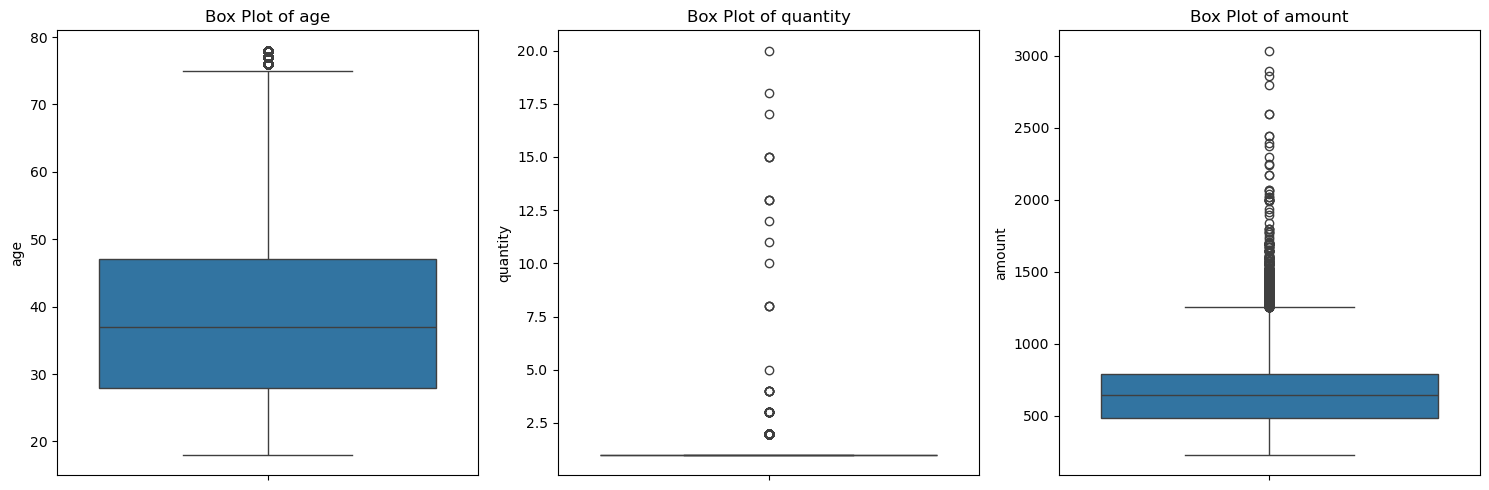

In [203]:

import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = ["age", "quantity", "amount"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, numerical_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Box Plot of {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.savefig("outlier_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()



In [24]:
df.to_csv("cleaned_df3.csv", index=False)

## Exploratory Data Analysis and Visualization

In [205]:
df.columns

Index(['index', 'order_id', 'customer_id', 'gender', 'age', 'age_group',
       'date', 'month', 'status', 'channel', 'sku', 'category', 'size',
       'quantity', 'currency', 'amount', 'ship_city', 'ship_state',
       'ship_postal_code', 'ship_country', 'b2b'],
      dtype='object')

In [207]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31047 entries, 0 to 31046
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   index             31047 non-null  int64         
 1   order_id          29967 non-null  object        
 2   customer_id       31006 non-null  object        
 3   gender            31047 non-null  object        
 4   age               31047 non-null  int64         
 5   age_group         31047 non-null  object        
 6   date              30559 non-null  datetime64[ns]
 7   month             30582 non-null  string        
 8   status            31047 non-null  string        
 9   channel           31047 non-null  string        
 10  sku               31047 non-null  string        
 11  category          31047 non-null  string        
 12  size              31047 non-null  object        
 13  quantity          31047 non-null  int64         
 14  currency          3104

In [209]:
df.to_csv("SwiftCart_Cleaned_Dataset.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Rows and columns:", df.shape)

Cleaned dataset saved successfully!
Rows and columns: (31047, 21)


In [211]:
from IPython.display import FileLink, display

display(FileLink("SwiftCart_Cleaned_Dataset.csv"))

C:\Users\Mahesh\SwiftCart_Cleaned_Dataset.csv